In [1]:
# =====================================================
# PATCH 1 : Import Libraries & Configuration
# =====================================================

import os
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger
)

from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")

print("TensorFlow Version :", tf.__version__)
print("Num GPUs Available :", len(tf.config.list_physical_devices('GPU')))

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE

IMG_SIZE = 224
BATCH_SIZE = 32

NUM_CLASSES = 17

TARGET_IMAGES_PER_CLASS = 1500

print("Everything Loaded Successfully ✅")

TensorFlow Version : 2.20.0
Num GPUs Available : 2
Everything Loaded Successfully ✅


In [2]:
# ==========================================================
# PATCH 2 : Read Original Dataset
# ==========================================================

ROOT = "/kaggle/input/datasets/shubham2703/five-crop-diseases-dataset/Crop Diseases Dataset/Crop Diseases/Crop___Disease"

print(ROOT)

data = []

label = 0
class_names = []

for crop in sorted(os.listdir(ROOT)):

    crop_path = os.path.join(ROOT, crop)

    if not os.path.isdir(crop_path):
        continue

    for disease in sorted(os.listdir(crop_path)):

        disease_path = os.path.join(crop_path, disease)

        if not os.path.isdir(disease_path):
            continue

        class_names.append(disease)

        for file in os.listdir(disease_path):

            if file.lower().endswith((".jpg", ".jpeg", ".png")):

                data.append([
                    os.path.join(disease_path, file),
                    crop,
                    disease,
                    label
                ])

        label += 1

df = pd.DataFrame(
    data,
    columns=[
        "filepath",
        "crop",
        "disease",
        "label"
    ]
)

print(df.head())

print("\nTotal Images :", len(df))
print("Total Classes :", len(class_names))

/kaggle/input/datasets/shubham2703/five-crop-diseases-dataset/Crop Diseases Dataset/Crop Diseases/Crop___Disease
                                            filepath  crop  \
0  /kaggle/input/datasets/shubham2703/five-crop-d...  Corn   
1  /kaggle/input/datasets/shubham2703/five-crop-d...  Corn   
2  /kaggle/input/datasets/shubham2703/five-crop-d...  Corn   
3  /kaggle/input/datasets/shubham2703/five-crop-d...  Corn   
4  /kaggle/input/datasets/shubham2703/five-crop-d...  Corn   

              disease  label  
0  Corn___Common_Rust      0  
1  Corn___Common_Rust      0  
2  Corn___Common_Rust      0  
3  Corn___Common_Rust      0  
4  Corn___Common_Rust      0  

Total Images : 13324
Total Classes : 17


disease
Bacterial Blight                100
Corn___Common_Rust             1192
Corn___Gray_Leaf_Spot           513
Corn___Healthy                 1162
Corn___Northern_Leaf_Blight     985
Healthy                         100
Potato___Early_Blight          1000
Potato___Healthy                152
Potato___Late_Blight           1000
Red Rot                         100
Rice___Brown_Spot               613
Rice___Healthy                 1488
Rice___Leaf_Blast               977
Rice___Neck_Blast              1000
Wheat___Brown_Rust              902
Wheat___Healthy                1116
Wheat___Yellow_Rust             924
dtype: int64
['Corn___Common_Rust', 'Corn___Gray_Leaf_Spot', 'Corn___Healthy', 'Corn___Northern_Leaf_Blight', 'Potato___Early_Blight', 'Potato___Healthy', 'Potato___Late_Blight', 'Rice___Brown_Spot', 'Rice___Healthy', 'Rice___Leaf_Blast', 'Rice___Neck_Blast', 'Wheat___Brown_Rust', 'Wheat___Healthy', 'Wheat___Yellow_Rust', 'Bacterial Blight', 'Healthy', 'Red Rot']


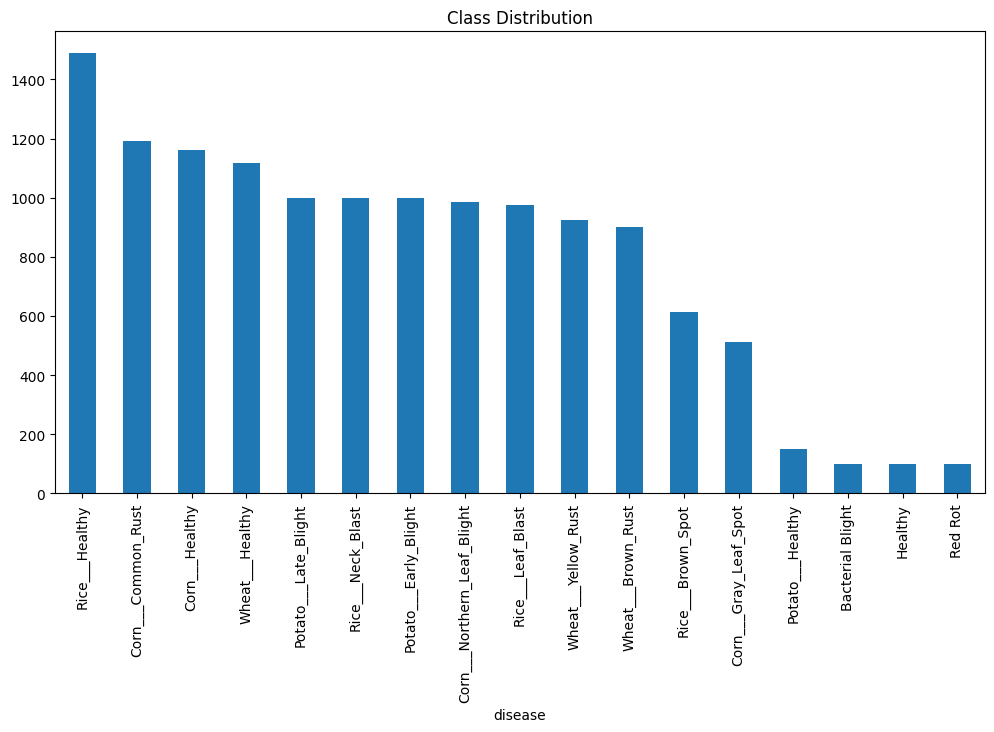

In [3]:
# ==========================================================
# PATCH 3 : Dataset Information
# ==========================================================

print("="*60)

print(df.groupby("disease").size())

print("="*60)

print(class_names)

print("="*60)

plt.figure(figsize=(12,6))

df["disease"].value_counts().plot(kind="bar")

plt.title("Class Distribution")

plt.xticks(rotation=90)

plt.show()

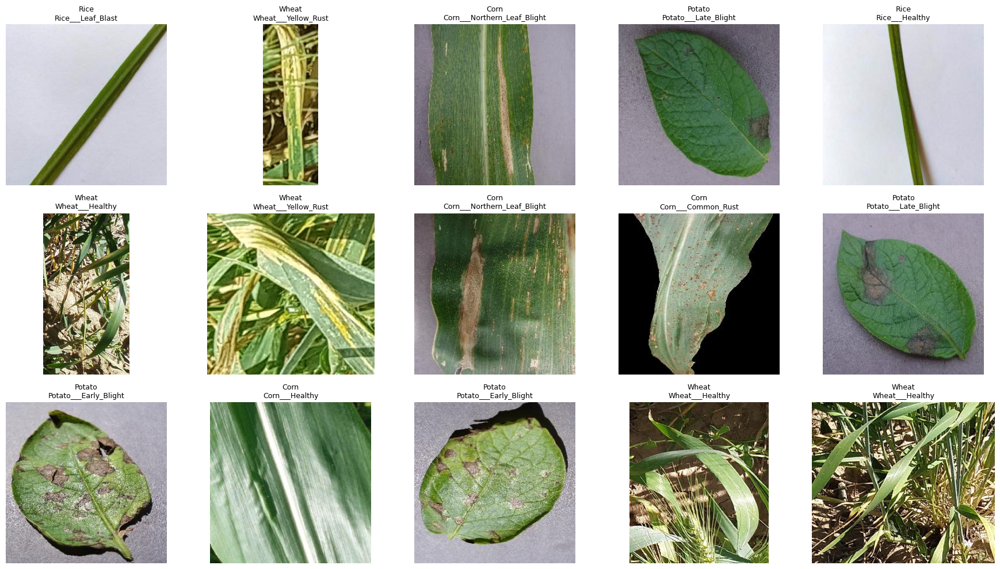

In [4]:
# ==========================================================
# PATCH 4 : Show Random Samples
# ==========================================================

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 5, figsize=(18, 10))

axes = axes.flatten()

for ax in axes:

    row = df.sample(n=1).iloc[0]

    img = Image.open(row["filepath"]).convert("RGB")

    ax.imshow(img)

    ax.set_title(
        f"{row['crop']}\n{row['disease']}",
        fontsize=9
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# ==========================================================
# PATCH 5 : Train Validation Test Split
# ==========================================================

train_df, test_df = train_test_split(
    df,
    test_size=0.10,
    stratify=df["label"],
    random_state=42
)

train_df, val_df = train_test_split(
    train_df,
    test_size=0.1111,
    stratify=train_df["label"],
    random_state=42
)

print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))

Train : 10658
Validation : 1333
Test : 1333


In [6]:
# ==========================================================
# PATCH 6 : Save CSV
# ==========================================================

train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("CSV Saved Successfully")

CSV Saved Successfully


In [7]:
# ==========================================================
# PATCH 7 : Verify Split
# ==========================================================

print(train_df["disease"].value_counts())

print()

print(val_df["disease"].value_counts())

print()

print(test_df["disease"].value_counts())

disease
Rice___Healthy                 1190
Corn___Common_Rust              954
Corn___Healthy                  930
Wheat___Healthy                 892
Rice___Neck_Blast               800
Potato___Late_Blight            800
Potato___Early_Blight           800
Corn___Northern_Leaf_Blight     787
Rice___Leaf_Blast               781
Wheat___Yellow_Rust             738
Wheat___Brown_Rust              722
Rice___Brown_Spot               491
Corn___Gray_Leaf_Spot           411
Potato___Healthy                122
Bacterial Blight                 80
Red Rot                          80
Healthy                          80
Name: count, dtype: int64

disease
Rice___Healthy                 149
Corn___Common_Rust             119
Corn___Healthy                 116
Wheat___Healthy                112
Rice___Neck_Blast              100
Potato___Early_Blight          100
Potato___Late_Blight           100
Corn___Northern_Leaf_Blight     99
Rice___Leaf_Blast               98
Wheat___Yellow_Rust           

In [8]:
# ==========================================================
# PATCH 8 : Create Balanced Dataset Folder
# ==========================================================

BALANCED_ROOT = "/kaggle/working/Balanced_Dataset"

TRAIN_DIR = os.path.join(BALANCED_ROOT, "train")

os.makedirs(TRAIN_DIR, exist_ok=True)

print(TRAIN_DIR)

/kaggle/working/Balanced_Dataset/train


In [9]:
# ==========================================================
# PATCH 9 : Offline Augmentation
# ==========================================================

from tensorflow.keras.preprocessing.image import ImageDataGenerator

augmentor = ImageDataGenerator(

    rotation_range=20,

    width_shift_range=0.15,

    height_shift_range=0.15,

    shear_range=0.15,

    zoom_range=0.20,

    brightness_range=[0.8,1.2],

    horizontal_flip=True,

    vertical_flip=False,

    fill_mode="nearest"
)

In [10]:
# ==========================================================
# PATCH 10 : Balance Dataset
# ==========================================================

TARGET_IMAGES = 1500

print("Balancing Dataset...")

for disease in sorted(train_df["disease"].unique()):

    save_dir = os.path.join(TRAIN_DIR, disease)

    os.makedirs(save_dir, exist_ok=True)

    class_df = train_df[train_df["disease"] == disease]

    image_paths = class_df["filepath"].tolist()

    print(f"{disease} : {len(image_paths)}")

Balancing Dataset...
Bacterial Blight : 80
Corn___Common_Rust : 954
Corn___Gray_Leaf_Spot : 411
Corn___Healthy : 930
Corn___Northern_Leaf_Blight : 787
Healthy : 80
Potato___Early_Blight : 800
Potato___Healthy : 122
Potato___Late_Blight : 800
Red Rot : 80
Rice___Brown_Spot : 491
Rice___Healthy : 1190
Rice___Leaf_Blast : 781
Rice___Neck_Blast : 800
Wheat___Brown_Rust : 722
Wheat___Healthy : 892
Wheat___Yellow_Rust : 738


In [11]:
# ==========================================================
# PATCH 11 : Copy Original Images
# ==========================================================

for disease in sorted(train_df["disease"].unique()):

    save_dir = os.path.join(TRAIN_DIR, disease)

    class_df = train_df[train_df["disease"] == disease]

    for img_path in class_df["filepath"]:

        shutil.copy(img_path, save_dir)

print("Original Images Copied")

Original Images Copied


In [12]:
# ==========================================================
# PATCH 12 : Generate Images Until 1500
# ==========================================================

TARGET_IMAGES = 1500

for disease in sorted(train_df["disease"].unique()):

    save_dir = os.path.join(TRAIN_DIR, disease)

    total = len(os.listdir(save_dir))

    class_df = train_df[train_df["disease"] == disease]

    image_paths = class_df["filepath"].tolist()

    print(f"\n{disease}")

    while total < TARGET_IMAGES:

        img_path = random.choice(image_paths)

        img = Image.open(img_path).convert("RGB")

        img = img.resize((224,224))

        x = np.array(img)

        x = np.expand_dims(x, axis=0)

        aug_iter = augmentor.flow(

            x,

            batch_size=1

        )

        batch = next(aug_iter)

        aug_img = Image.fromarray(batch[0].astype("uint8"))

        aug_img.save(

            os.path.join(

                save_dir,

                f"aug_{total}.jpg"

            )

        )

        total += 1

    print("Total Images :", total)

print("\nBalanced Dataset Created Successfully")


Bacterial Blight
Total Images : 1500

Corn___Common_Rust
Total Images : 1500

Corn___Gray_Leaf_Spot
Total Images : 1500

Corn___Healthy
Total Images : 1500

Corn___Northern_Leaf_Blight
Total Images : 1500

Healthy
Total Images : 1500

Potato___Early_Blight
Total Images : 1500

Potato___Healthy
Total Images : 1500

Potato___Late_Blight
Total Images : 1500

Red Rot
Total Images : 1500

Rice___Brown_Spot
Total Images : 1500

Rice___Healthy
Total Images : 1500

Rice___Leaf_Blast
Total Images : 1500

Rice___Neck_Blast
Total Images : 1500

Wheat___Brown_Rust
Total Images : 1500

Wheat___Healthy
Total Images : 1500

Wheat___Yellow_Rust
Total Images : 1500

Balanced Dataset Created Successfully


,Disease,Images
0,Bacterial Blight,1500
1,Corn___Common_Rust,1500
2,Corn___Gray_Leaf_Spot,1500
3,Corn___Healthy,1500
4,Corn___Northern_Leaf_Blight,1500
5,Healthy,1500
6,Potato___Early_Blight,1500
7,Potato___Healthy,1500
8,Potato___Late_Blight,1500
9,Red Rot,1500


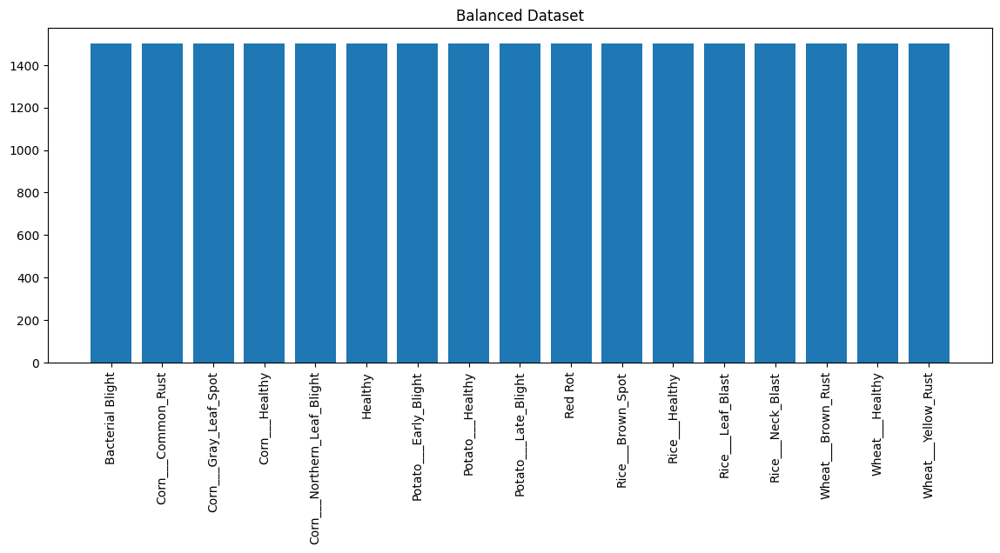

In [13]:
# ==========================================================
# PATCH 13 : Verify Balanced Dataset
# ==========================================================

counts = {}

for cls in sorted(os.listdir(TRAIN_DIR)):

    counts[cls] = len(os.listdir(os.path.join(TRAIN_DIR, cls)))

balance_df = pd.DataFrame({

    "Disease": counts.keys(),

    "Images": counts.values()

})

display(balance_df)

plt.figure(figsize=(14,5))

plt.bar(balance_df["Disease"], balance_df["Images"])

plt.xticks(rotation=90)

plt.title("Balanced Dataset")

plt.show()

In [14]:
# ==========================================================
# PATCH 14 : Validation Dataset
# ==========================================================

VAL_DIR = os.path.join(BALANCED_ROOT, "validation")

os.makedirs(VAL_DIR, exist_ok=True)

for disease in sorted(val_df["disease"].unique()):

    dst = os.path.join(VAL_DIR, disease)

    os.makedirs(dst, exist_ok=True)

    temp = val_df[val_df["disease"] == disease]

    for img in temp["filepath"]:

        shutil.copy(img, dst)

print("Validation Dataset Ready")

Validation Dataset Ready


In [15]:
# ==========================================================
# PATCH 15 : Test Dataset
# ==========================================================

TEST_DIR = os.path.join(BALANCED_ROOT, "test")

os.makedirs(TEST_DIR, exist_ok=True)

for disease in sorted(test_df["disease"].unique()):

    dst = os.path.join(TEST_DIR, disease)

    os.makedirs(dst, exist_ok=True)

    temp = test_df[test_df["disease"] == disease]

    for img in temp["filepath"]:

        shutil.copy(img, dst)

print("Test Dataset Ready")

Test Dataset Ready


In [16]:
# ==========================================================
# PATCH 16 : Load Balanced Dataset
# ==========================================================

import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_DIR,

    image_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    shuffle=True,

    seed=SEED

)

val_ds = tf.keras.utils.image_dataset_from_directory(

    VAL_DIR,

    image_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    shuffle=False

)

test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    shuffle=False

)

class_names = train_ds.class_names

NUM_CLASSES = len(class_names)

print(class_names)

print("Classes :", NUM_CLASSES)

Found 25500 files belonging to 17 classes.


I0000 00:00:1784992034.239358      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1784992034.242119      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 1333 files belonging to 17 classes.
Found 1333 files belonging to 17 classes.
['Bacterial Blight', 'Corn___Common_Rust', 'Corn___Gray_Leaf_Spot', 'Corn___Healthy', 'Corn___Northern_Leaf_Blight', 'Healthy', 'Potato___Early_Blight', 'Potato___Healthy', 'Potato___Late_Blight', 'Red Rot', 'Rice___Brown_Spot', 'Rice___Healthy', 'Rice___Leaf_Blast', 'Rice___Neck_Blast', 'Wheat___Brown_Rust', 'Wheat___Healthy', 'Wheat___Yellow_Rust']
Classes : 17


In [17]:
# ==========================================================
# PATCH 17 : Optimize tf.data
# ==========================================================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache()

train_ds = train_ds.shuffle(2000)

train_ds = train_ds.prefetch(AUTOTUNE)

val_ds = val_ds.cache().prefetch(AUTOTUNE)

test_ds = test_ds.cache().prefetch(AUTOTUNE)

print("Pipeline Ready")

Pipeline Ready


In [18]:
# ==========================================================
# PATCH 18 : Dataset Information
# ==========================================================

print("Train Batches :", tf.data.experimental.cardinality(train_ds).numpy())

print("Validation Batches :", tf.data.experimental.cardinality(val_ds).numpy())

print("Test Batches :", tf.data.experimental.cardinality(test_ds).numpy())

print()

print("Classes")

for i,c in enumerate(class_names):

    print(i,c)

Train Batches : 797
Validation Batches : 42
Test Batches : 42

Classes
0 Bacterial Blight
1 Corn___Common_Rust
2 Corn___Gray_Leaf_Spot
3 Corn___Healthy
4 Corn___Northern_Leaf_Blight
5 Healthy
6 Potato___Early_Blight
7 Potato___Healthy
8 Potato___Late_Blight
9 Red Rot
10 Rice___Brown_Spot
11 Rice___Healthy
12 Rice___Leaf_Blast
13 Rice___Neck_Blast
14 Wheat___Brown_Rust
15 Wheat___Healthy
16 Wheat___Yellow_Rust


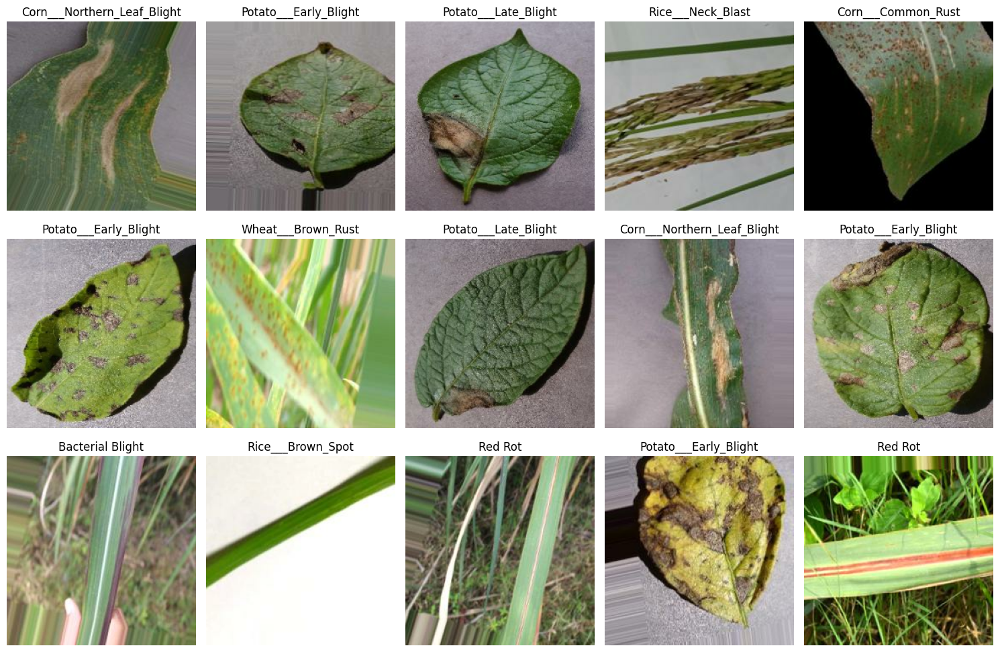

In [19]:
# ==========================================================
# PATCH 19 : Show Batch
# ==========================================================

plt.figure(figsize=(15,10))

for images,labels in train_ds.take(1):

    for i in range(15):

        plt.subplot(3,5,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.tight_layout()

plt.show()

In [20]:
# ==========================================================
# PATCH 20 : Online Augmentation
# ==========================================================

from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.10),

    layers.RandomZoom(0.10),

    layers.RandomContrast(0.10),

    layers.RandomTranslation(0.10,0.10)

])

data_augmentation

<Sequential name=sequential, built=False>

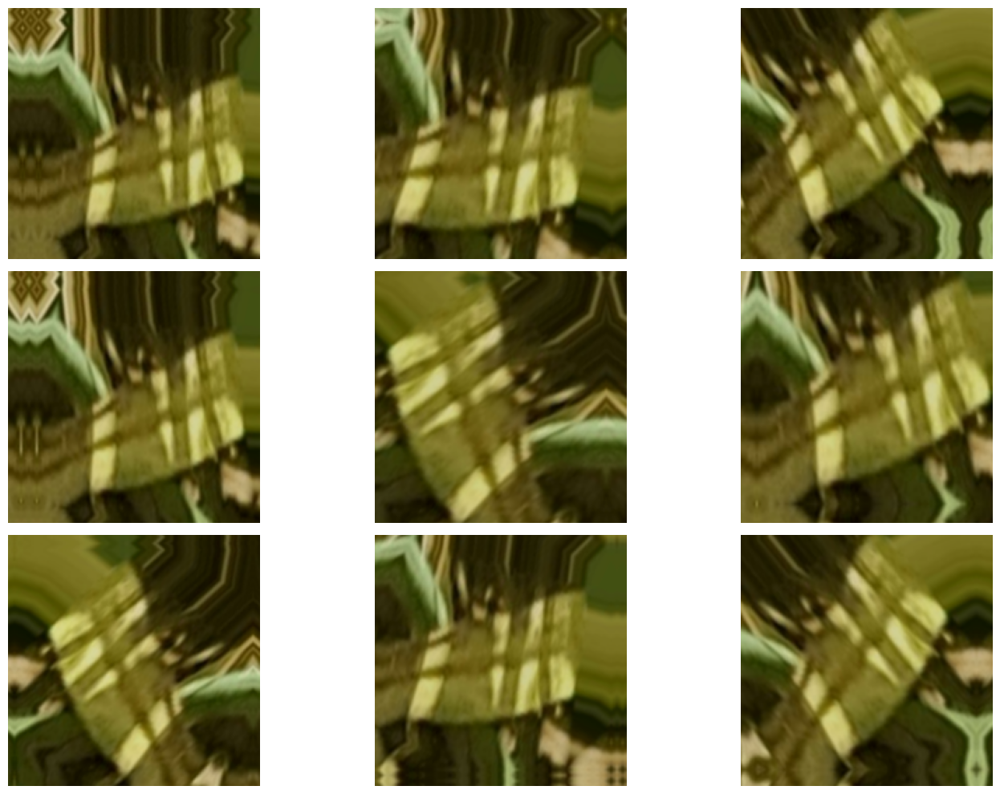

In [21]:
# ==========================================================
# PATCH 21 : Visualize Augmentation
# ==========================================================

plt.figure(figsize=(15,10))

for images,_ in train_ds.take(1):

    img = images[0]

    for i in range(9):

        plt.subplot(3,3,i+1)

        aug = data_augmentation(tf.expand_dims(img,0))

        plt.imshow(aug[0].numpy().astype("uint8"))

        plt.axis("off")

plt.tight_layout()

plt.show()

In [22]:
# ==========================================================
# Verify Balanced Dataset
# ==========================================================

import os
import pandas as pd

def count_images(folder):

    result = {}

    for cls in sorted(os.listdir(folder)):

        cls_path = os.path.join(folder, cls)

        if os.path.isdir(cls_path):

            result[cls] = len([
                f for f in os.listdir(cls_path)
                if f.lower().endswith((".jpg",".jpeg",".png"))
            ])

    return pd.DataFrame(
        result.items(),
        columns=["Disease","Images"]
    )

print("TRAIN")
display(count_images(TRAIN_DIR))

print("VALIDATION")
display(count_images(VAL_DIR))

print("TEST")
display(count_images(TEST_DIR))

TRAIN


,Disease,Images
0,Bacterial Blight,1500
1,Corn___Common_Rust,1500
2,Corn___Gray_Leaf_Spot,1500
3,Corn___Healthy,1500
4,Corn___Northern_Leaf_Blight,1500
5,Healthy,1500
6,Potato___Early_Blight,1500
7,Potato___Healthy,1500
8,Potato___Late_Blight,1500
9,Red Rot,1500


VALIDATION


,Disease,Images
0,Bacterial Blight,10
1,Corn___Common_Rust,119
2,Corn___Gray_Leaf_Spot,51
3,Corn___Healthy,116
4,Corn___Northern_Leaf_Blight,99
5,Healthy,10
6,Potato___Early_Blight,100
7,Potato___Healthy,15
8,Potato___Late_Blight,100
9,Red Rot,10


TEST


,Disease,Images
0,Bacterial Blight,10
1,Corn___Common_Rust,119
2,Corn___Gray_Leaf_Spot,51
3,Corn___Healthy,116
4,Corn___Northern_Leaf_Blight,99
5,Healthy,10
6,Potato___Early_Blight,100
7,Potato___Healthy,15
8,Potato___Late_Blight,100
9,Red Rot,10


In [23]:
# ==========================================================
# Create Final Dataset Folder
# ==========================================================

FINAL_DATASET = "/kaggle/working/Balanced_Dataset"

os.makedirs(FINAL_DATASET, exist_ok=True)

print(FINAL_DATASET)

/kaggle/working/Balanced_Dataset


In [24]:
# ==========================================================
# Zip Complete Dataset
# ==========================================================

import shutil

ZIP_PATH = shutil.make_archive(

    "/kaggle/working/Balanced_Dataset",

    "zip",

    FINAL_DATASET

)

print(ZIP_PATH)

/kaggle/working/Balanced_Dataset.zip


In [25]:
import os

size = os.path.getsize("/kaggle/working/Balanced_Dataset.zip")/(1024**3)

print(f"ZIP Size : {size:.2f} GB")

ZIP Size : 4.45 GB


In [26]:
# ==========================================================
# PATCH 22 : DenseNet121
# ==========================================================

from tensorflow.keras.applications import DenseNet121

base_model = DenseNet121(

    include_top=False,

    weights="imagenet",

    input_shape=(224,224,3)

)

base_model.trainable = False

print(base_model.summary())

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "densenet121"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,037,504 (26.85 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 7,037,504 (26.85 MB)

None


In [27]:
# ==========================================================
# PATCH 23 : Build Model
# ==========================================================

from tensorflow.keras import Model
from tensorflow.keras.layers import *

inputs = Input(shape=(224,224,3))

x = data_augmentation(inputs)

x = tf.keras.applications.densenet.preprocess_input(x)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dropout(0.40)(x)

x = Dense(512,activation="relu")(x)

x = BatchNormalization()(x)

x = Dropout(0.30)(x)

outputs = Dense(NUM_CLASSES,activation="softmax")(x)

model = Model(inputs,outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add (Add)                       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 17)             │         8,721 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,577,169 (28.90 MB)

 Trainable params: 536,593 (2.05 MB)

 Non-trainable params: 7,040,576 (26.86 MB)

In [29]:
# ==========================================================
# PATCH 24 : Compile DenseNet121
# ==========================================================

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

optimizer = Adam(
    learning_rate=3e-4
)

loss = tf.keras.losses.SparseCategoricalCrossentropy()

model.compile(

    optimizer=optimizer,

    loss=loss,

    metrics=[
        "accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5_accuracy"
        )
    ]
)

print("Model Compiled Successfully")

Model Compiled Successfully


In [30]:
# ==========================================================
# PATCH 25 : Callbacks
# ==========================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    CSVLogger
)

checkpoint = ModelCheckpoint(

    "DenseNet121_Best.keras",

    monitor="val_accuracy",

    save_best_only=True,

    verbose=1

)

earlystop = EarlyStopping(

    monitor="val_loss",

    patience=6,

    restore_best_weights=True,

    verbose=1

)

reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.2,

    patience=3,

    min_lr=1e-6,

    verbose=1

)

csv_logger = CSVLogger(

    "training_log.csv",

    append=False

)

callbacks = [

    checkpoint,

    earlystop,

    reduce_lr,

    csv_logger

]

print("Callbacks Ready")

Callbacks Ready


In [31]:
# ==========================================================
# PATCH 26 : Initial Training
# ==========================================================

INITIAL_EPOCHS = 20

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=INITIAL_EPOCHS,

    callbacks=callbacks

)

Epoch 1/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.6816 - loss: 0.9604 - top5_accuracy: 0.9344
Epoch 1: val_accuracy improved from None to 0.89872, saving model to DenseNet121_Best.keras

Epoch 1: finished saving model to DenseNet121_Best.keras
797/797 ━━━━━━━━━━━━━━━━━━━━ 156s 169ms/step - accuracy: 0.7849 - loss: 0.5906 - top5_accuracy: 0.9836 - val_accuracy: 0.8987 - val_loss: 0.2314 - val_top5_accuracy: 1.0000 - learning_rate: 3.0000e-04
Epoch 2/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.8609 - loss: 0.3518 - top5_accuracy: 0.9994
Epoch 2: val_accuracy improved from 0.89872 to 0.90998, saving model to DenseNet121_Best.keras

Epoch 2: finished saving model to DenseNet121_Best.keras
797/797 ━━━━━━━━━━━━━━━━━━━━ 125s 157ms/step - accuracy: 0.8629 - loss: 0.3426 - top5_accuracy: 0.9995 - val_accuracy: 0.9100 - val_loss: 0.2077 - val_top5_accuracy: 0.9992 - learning_rate: 3.0000e-04
Epoch 3/20
797/797 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.881

In [32]:
# ==========================================================
# PATCH 27 : Load Best Model
# ==========================================================

model.load_weights("DenseNet121_Best.keras")

print("Best Weights Loaded")

Best Weights Loaded


In [33]:
# ==========================================================
# PATCH 28 : Fine Tuning
# ==========================================================

base_model.trainable = True

for layer in base_model.layers[:-80]:

    layer.trainable = False

print("Trainable Layers")

print(sum([l.trainable for l in model.layers]))

Trainable Layers
10


In [35]:
# ==========================================================
# PATCH 29 : Recompile for Fine-Tuning
# ==========================================================

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

model.compile(

    optimizer=Adam(learning_rate=1e-5),

    loss=SparseCategoricalCrossentropy(),

    metrics=[
        "accuracy",
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5_accuracy"
        )
    ]

)

print("Model Recompiled Successfully")

Model Recompiled Successfully


In [36]:
# ==========================================================
# PATCH 30 : Fine Tune
# ==========================================================

FINE_TUNE_EPOCHS = 15

history_fine = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=FINE_TUNE_EPOCHS,

    callbacks=callbacks

)

Epoch 1/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.9242 - loss: 0.1894 - top5_accuracy: 1.0000
Epoch 1: val_accuracy did not improve from 0.94074
797/797 ━━━━━━━━━━━━━━━━━━━━ 176s 188ms/step - accuracy: 0.9260 - loss: 0.1866 - top5_accuracy: 1.0000 - val_accuracy: 0.9370 - val_loss: 0.1586 - val_top5_accuracy: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.9325 - loss: 0.1773 - top5_accuracy: 1.0000
Epoch 2: val_accuracy did not improve from 0.94074
797/797 ━━━━━━━━━━━━━━━━━━━━ 145s 182ms/step - accuracy: 0.9335 - loss: 0.1724 - top5_accuracy: 1.0000 - val_accuracy: 0.9377 - val_loss: 0.1567 - val_top5_accuracy: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/15
797/797 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.9340 - loss: 0.1652 - top5_accuracy: 0.9999
Epoch 3: val_accuracy improved from 0.94074 to 0.94299, saving model to DenseNet121_Best.keras

Epoch 3: finished saving model to DenseNet121_Best.keras
797/797

In [37]:
# ==========================================================
# PATCH 31 : Save Final Model
# ==========================================================

model.save(

    "DenseNet121_Final.keras"

)

print("Model Saved")

Model Saved


In [38]:
# ==========================================================
# PATCH 32 : Evaluation
# ==========================================================

loss, accuracy, top5 = model.evaluate(test_ds)

print()

print("Test Loss :", loss)

print("Test Accuracy :", accuracy)

print("Top5 Accuracy :", top5)

42/42 ━━━━━━━━━━━━━━━━━━━━ 7s 156ms/step - accuracy: 0.9580 - loss: 0.1236 - top5_accuracy: 0.9992

Test Loss : 0.12363371253013611
Test Accuracy : 0.957989513874054
Top5 Accuracy : 0.9992498159408569


In [40]:
# ==========================================================
# PATCH 33 : Save History
# ==========================================================

history_dict = history.history

history_fine_dict = history_fine.history

import json

with open("history.json","w") as f:

    json.dump(history_dict,f)

with open("history_fine.json","w") as f:

    json.dump(history_fine_dict,f)

print("History Saved")

History Saved


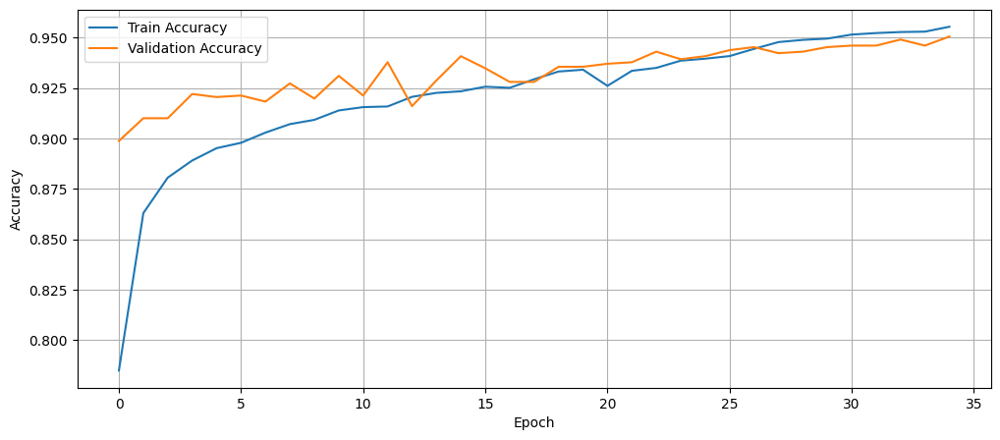

In [41]:
# ==========================================================
# PATCH 34 : Training Curves
# ==========================================================

import matplotlib.pyplot as plt

history_all = {}

history_all["accuracy"] = history.history["accuracy"] + history_fine.history["accuracy"]
history_all["val_accuracy"] = history.history["val_accuracy"] + history_fine.history["val_accuracy"]

history_all["loss"] = history.history["loss"] + history_fine.history["loss"]
history_all["val_loss"] = history.history["val_loss"] + history_fine.history["val_loss"]

plt.figure(figsize=(12,5))

plt.plot(history_all["accuracy"], label="Train Accuracy")
plt.plot(history_all["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig("Training_Accuracy.png", dpi=300)

plt.show()

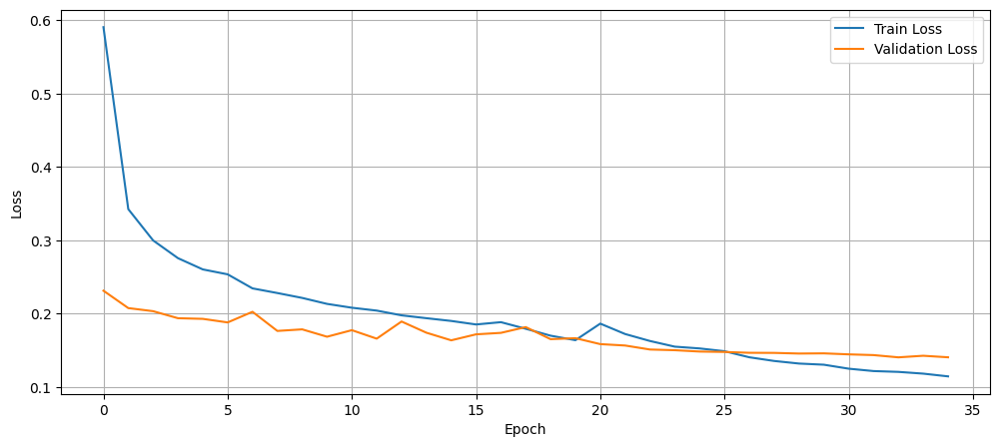

In [43]:
plt.figure(figsize=(12,5))

plt.plot(history_all["loss"], label="Train Loss")
plt.plot(history_all["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig("Training_Loss.png", dpi=300)

plt.show()

In [44]:
# ==========================================================
# PATCH 35 : Predict Test Dataset
# ==========================================================

import numpy as np

y_true = []
y_pred = []
y_prob = []

for images, labels in test_ds:

    preds = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())

    y_pred.extend(np.argmax(preds, axis=1))

    y_prob.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Prediction Completed")

Prediction Completed


In [45]:
# ==========================================================
# PATCH 36 : Classification Report
# ==========================================================

from sklearn.metrics import classification_report

report = classification_report(

    y_true,

    y_pred,

    target_names=class_names,

    digits=4,

    output_dict=True

)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv("Classification_Report.csv")

display(report_df)

,precision,recall,f1-score,support
Bacterial Blight,1.000000,0.900000,0.947368,10.000000
Corn___Common_Rust,0.991667,1.000000,0.995816,119.000000
Corn___Gray_Leaf_Spot,0.925926,0.980392,0.952381,51.000000
Corn___Healthy,1.000000,1.000000,1.000000,116.000000
Corn___Northern_Leaf_Blight,0.989583,0.959596,0.974359,99.000000
Healthy,1.000000,1.000000,1.000000,10.000000
Potato___Early_Blight,1.000000,1.000000,1.000000,100.000000
Potato___Healthy,1.000000,1.000000,1.000000,15.000000
Potato___Late_Blight,1.000000,1.000000,1.000000,100.000000
Red Rot,0.909091,1.000000,0.952381,10.000000


In [46]:
txt_report = classification_report(

    y_true,

    y_pred,

    target_names=class_names,

    digits=4

)

with open("Classification_Report.txt","w") as f:

    f.write(txt_report)

print(txt_report)

                             precision    recall  f1-score   support

           Bacterial Blight     1.0000    0.9000    0.9474        10
         Corn___Common_Rust     0.9917    1.0000    0.9958       119
      Corn___Gray_Leaf_Spot     0.9259    0.9804    0.9524        51
             Corn___Healthy     1.0000    1.0000    1.0000       116
Corn___Northern_Leaf_Blight     0.9896    0.9596    0.9744        99
                    Healthy     1.0000    1.0000    1.0000        10
      Potato___Early_Blight     1.0000    1.0000    1.0000       100
           Potato___Healthy     1.0000    1.0000    1.0000        15
       Potato___Late_Blight     1.0000    1.0000    1.0000       100
                    Red Rot     0.9091    1.0000    0.9524        10
          Rice___Brown_Spot     0.8727    0.7869    0.8276        61
             Rice___Healthy     0.8343    0.9463    0.8868       149
          Rice___Leaf_Blast     0.8333    0.7143    0.7692        98
          Rice___Neck_Blast     1

<Figure size 1500x1500 with 0 Axes>

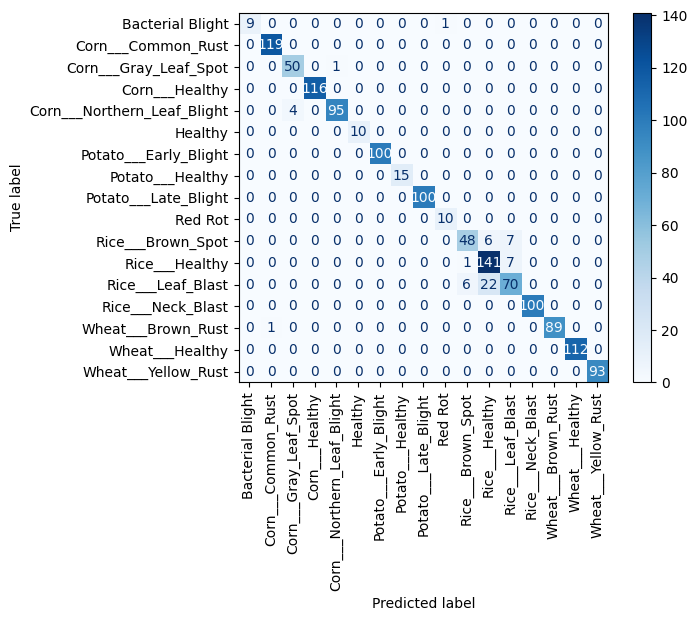

In [47]:
# ==========================================================
# PATCH 38 : Confusion Matrix
# ==========================================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(15,15))

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=class_names

)

disp.plot(

    xticks_rotation=90,

    cmap="Blues"

)

plt.savefig("Confusion_Matrix.png", dpi=300)

plt.show()

In [48]:
# ==========================================================
# PATCH 39 : Overall Metrics
# ==========================================================

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_true,y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

metrics_df = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1
    ]

})

display(metrics_df)

metrics_df.to_csv("Overall_Metrics.csv",index=False)

,Metric,Value
0,Accuracy,0.957989
1,Precision,0.958370
2,Recall,0.957989
3,F1 Score,0.957261


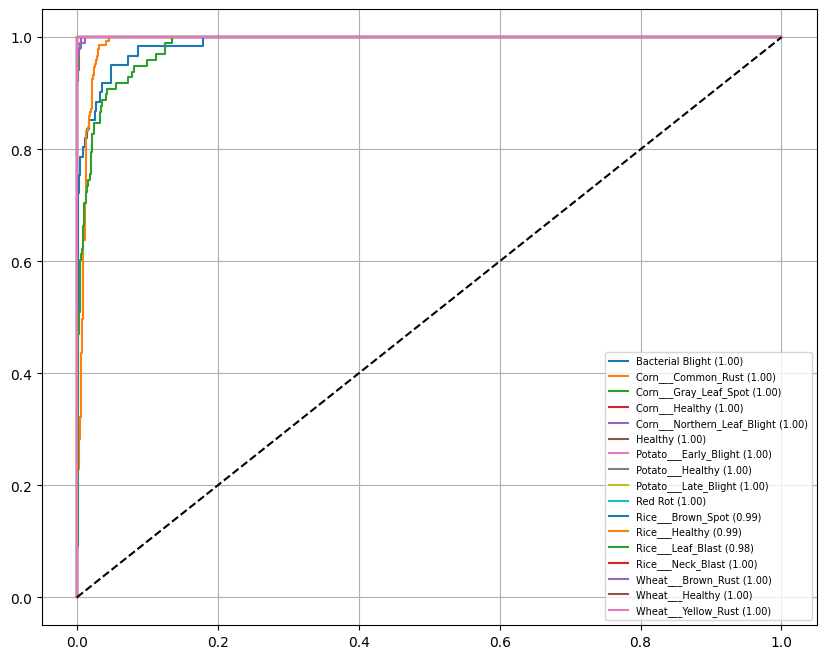

In [49]:
# ==========================================================
# PATCH 40 : ROC Curve
# ==========================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_true_bin = label_binarize(
    y_true,
    classes=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(10,8))

for i in range(NUM_CLASSES):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:,i],
        y_prob[:,i]
    )

    roc_auc = auc(fpr,tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_names[i]} ({roc_auc:.2f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.legend(fontsize=7)

plt.grid()

plt.savefig("ROC_Curve.png",dpi=300)

plt.show()

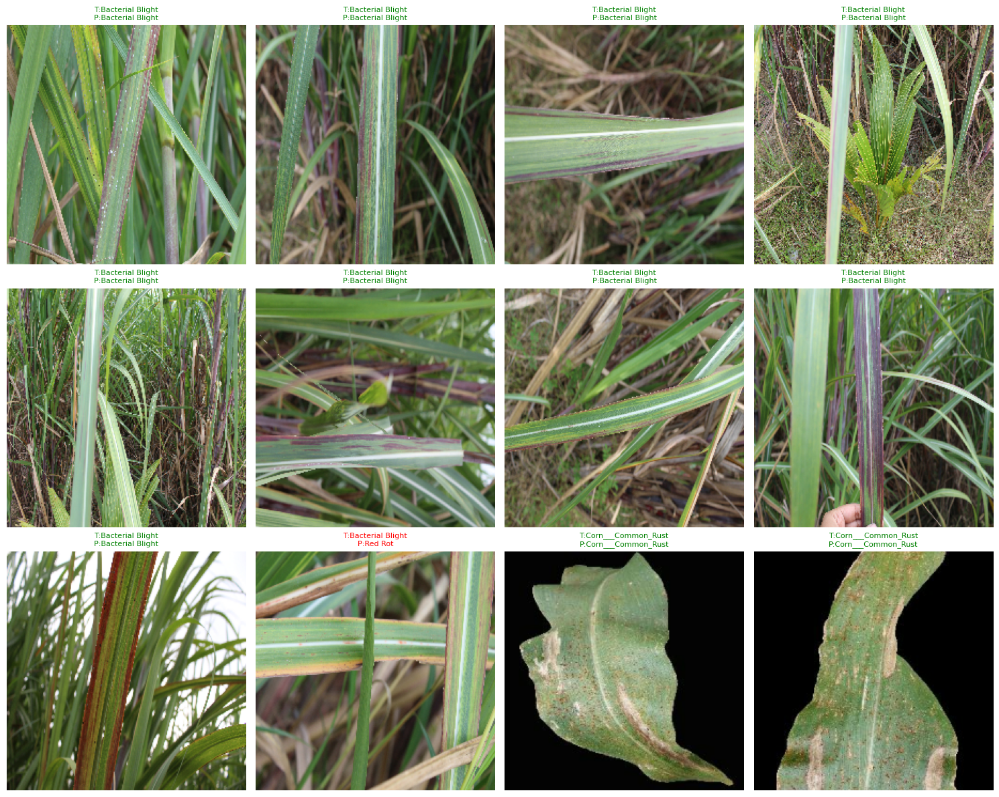

In [51]:
# ==========================================================
# PATCH 41 : Random Predictions
# ==========================================================

plt.figure(figsize=(15,12))

for images, labels in test_ds.take(1):

    preds = model.predict(images, verbose=0)

    pred_class = np.argmax(preds, axis=1)

    for i in range(12):

        plt.subplot(3,4,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        color = "green" if pred_class[i]==labels[i] else "red"

        plt.title(

            f"T:{class_names[labels[i]]}\nP:{class_names[pred_class[i]]}",

            color=color,

            fontsize=8

        )

        plt.axis("off")

plt.tight_layout()

plt.savefig("Sample_Predictions.png",dpi=300)

plt.show()

In [52]:
# ==========================================================
# PATCH 42 : Create Results Folder
# ==========================================================

import shutil
import os

RESULTS = "Results"

os.makedirs(RESULTS,exist_ok=True)

files = [

"Training_Accuracy.png",

"Training_Loss.png",

"Classification_Report.csv",

"Classification_Report.txt",

"Overall_Metrics.csv",

"Confusion_Matrix.png",

"ROC_Curve.png",

"Sample_Predictions.png",

"DenseNet121_Final.keras",

"DenseNet121_Best.keras",

"training_log.csv"

]

for file in files:

    if os.path.exists(file):

        shutil.copy(file, RESULTS)

print("Results Saved")

Results Saved


In [53]:
# ==========================================================
# PATCH 43 : Zip Results
# ==========================================================

import shutil

shutil.make_archive(

    "DenseNet121_Project",

    "zip",

    "Results"

)

print("ZIP Created Successfully")

ZIP Created Successfully


In [1]:
# ==========================================================
# Convert Saved .keras Model
# ==========================================================

import tensorflow as tf

MODEL_PATH = "/kaggle/input/models/azazurrehman88/plant-disease/keras/default/1/DenseNet121_Final.keras"

model = tf.keras.models.load_model(MODEL_PATH)

converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("DenseNet121_Final.tflite", "wb") as f:
    f.write(tflite_model)

print("✅ Conversion Completed")

I0000 00:00:1785002656.023582      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785002656.026760      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


INFO:tensorflow:Assets written to: /tmp/tmp7ptn8gfv/assets


INFO:tensorflow:Assets written to: /tmp/tmp7ptn8gfv/assets


Saved artifact at '/tmp/tmp7ptn8gfv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 17), dtype=tf.float32, name=None)
Captures:
  134101900517712: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  134101900517904: TensorSpec(shape=(3,), dtype=tf.float32, name=None)
  134104589762832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134104589764752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134104589765520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134104589764176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134104589763024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134104589766096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134104589766288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134104589765712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13

W0000 00:00:1785002681.513848      58 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1785002681.513892      58 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1785002681.895621      58 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


✅ Conversion Completed


In [2]:
import os

print(os.path.exists("DenseNet121_Final.tflite"))

print(f"Model Size: {os.path.getsize('DenseNet121_Final.tflite')/(1024*1024):.2f} MB")

True
Model Size: 28.65 MB


In [ ]:
# ==========================================
# PATCH 32 : Install Gradio
# ==========================================
!pip install -q gradio

# ==========================================
# PATCH 33 : Imports
# ==========================================
import gradio as gr
import tensorflow as tf
import numpy as np
from PIL import Image

# ==========================================
# PATCH 34 : Load Trained Model
# ==========================================
MODEL_PATH = "/kaggle/working/DenseNet121_Final.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model Loaded Successfully!")
print("Output Shape:", model.output_shape)

# ==========================================
# PATCH 35 : Class Names
# (must match the LabelEncoder order used during training)
# ==========================================
class_names = [
    "Bacterial Blight",
    "Corn___Common_Rust",
    "Corn___Gray_Leaf_Spot",
    "Corn___Healthy",
    "Corn___Northern_Leaf_Blight",
    "Healthy",
    "Potato___Early_Blight",
    "Potato___Healthy",
    "Potato___Late_Blight",
    "Red Rot",
    "Rice___Brown_Spot",
    "Rice___Healthy",
    "Rice___Leaf_Blast",
    "Rice___Neck_Blast",
    "Wheat___Brown_Rust",
    "Wheat___Healthy",
    "Wheat___Yellow_Rust"
]

assert model.output_shape[-1] == len(class_names), "Class count mismatch with model output!"

# ==========================================
# PATCH 36 : Predict Function
# NOTE: preprocess_input is already applied INSIDE the model
# (see Patch 14 — do NOT normalize again here)
# ==========================================
IMG_SIZE = 224

def predict(image):

    if image is None:
        return {}

    image = image.convert("RGB")
    image = image.resize((IMG_SIZE, IMG_SIZE))

    img = np.array(image).astype(np.float32)   # raw 0-255 pixels — model handles preprocessing
    img = np.expand_dims(img, axis=0)

    prediction = model.predict(img, verbose=0)[0]

    top5_idx = np.argsort(prediction)[::-1][:5]

    results = {class_names[idx]: float(prediction[idx]) for idx in top5_idx}

    return results

# ==========================================
# PATCH 37 : Gradio Interface
# ==========================================
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=5),
    title="🌿 Plant Disease Detection",
    description="Upload a plant leaf image to detect the disease.",
    examples=None
)

demo.launch(debug=True, share=True)

Model Loaded Successfully!
Output Shape: (None, 17)
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://2dc776b498b938fb04.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
